# WEEK6 知识精讲：NumPy 数组与随机统计

> **中文说明**：本 notebook 依据 `WEEK6/source/lec4 Ver2.ipynb` 和 `WEEK6/source/lec5.ipynb` 重写。Part I 把 NumPy 数组的核心操作串成一条线；Part II 讲随机数、常见统计分布、Seaborn 可视化和 ufunc。所有代码块都已真实运行，下面的输出就是运行结果；练习答案默认折叠，建议先自己做。

**怎么用这份笔记**

1. 先读文字说明，再运行代码，最后遮住答案做 `Exercise`。
2. 一个代码块尽量只讲一件事，输出下面通常紧跟一句“怎么看这个结果”。
3. 标有 **注意** 的地方是作业和考试里最容易踩的坑。

## 目录

### Part I · NumPy 数组（lec4 Ver2）
1. 从 Python list 到 ndarray
2. 数组属性
3. 创建数组
4. 索引
5. 切片
6. 布尔索引
7. 视图与副本
8. 改变形状：reshape / resize / newaxis
9. 拼接与拆分
10. 遍历数组
11. 逐元素运算、点积与广播
12. 转置与 dtype 转换
13. 聚合函数与 axis
14. 排序

### Part II · 随机数与统计分布（lec5）
15. 伪随机数与随机种子
16. 从已有数组中抽样
17. 用 Seaborn 可视化分布
18. 常见统计分布
19. ufunc：向量化函数
20. 速查表与常见坑

---

# Part I · NumPy 数组（lec4 Ver2）

> WEEK4 已经系统讲过数组；`lec4 Ver2` 是同一主题的修订版。这一部分保留完整、可运行的例子，并特别标出 Ver2 强调的细节（`base`、维度升降、`argmax` 的 axis、二维排序等）。如果刚学完 WEEK4，可以快速过一遍，把重点放在第 7、8、13、14 节。

## 1. 从 Python list 到 ndarray

Python 的 `list` 很灵活，可以装不同类型；但它**没有为数值计算优化**：
- 元素是分散存放的，逐个循环很慢；
- `+` 和 `*` 的含义是“拼接”和“重复”，不是逐元素运算。

`numpy.ndarray` 的核心特点是：**同一种 dtype + 连续内存 + 支持向量化运算**。

| 表达式 | Python list | NumPy array |
|---|---|---|
| `L * 3` / `b * 3` | 把列表重复 3 遍 | 每个元素乘 3 |
| `L + L` / `b + b` | 把列表拼起来 | 每个元素相加 |

一句话：**列表适合“装东西”，NumPy 数组适合“算数学”。**

In [1]:
import numpy as np

L = [1, 2, 3]
b = np.array([1, 2, 3])

print("list  L * 3 :", L * 3)
print("array b * 3 :", b * 3)
print("list  L + L :", L + L)
print("array b + b :", b + b)
print("type(b)     :", type(b))

list  L * 3 : [1, 2, 3, 1, 2, 3, 1, 2, 3]
array b * 3 : [3 6 9]
list  L + L : [1, 2, 3, 1, 2, 3]
array b + b : [2 4 6]
type(b)     : <class 'numpy.ndarray'>


标准库的 `array` 模块也能存“同类型、连续内存”的数组，但功能非常有限；NumPy 才是数值计算的主力。

In [2]:
import array

a = array.array('i', range(5))   # 'i' = signed int
print(a)
print("type:", type(a))

array('i', [0, 1, 2, 3, 4])
type: <class 'array.array'>


## 2. 数组属性

不用死记，用属性就能查看数组的维度、形状、元素个数和内存占用。

| 属性 | 含义 |
|---|---|
| `ndim` | 维度数（axes 的个数） |
| `shape` | 每个维度的大小，返回 tuple |
| `size` | 元素总数 |
| `dtype` | 元素类型 |
| `itemsize` | 单个元素占多少字节 |
| `nbytes` | 整个数组占多少字节，等于 `size * itemsize` |
| `base` | 如果数组是视图，指向原始数组；如果自己拥有内存，则为 `None` |

In [3]:
x = np.array([[1, 2, 3],
              [4, 5, 6]])

print("x.ndim    :", x.ndim)
print("x.shape   :", x.shape)
print("x.size    :", x.size)
print("x.dtype   :", x.dtype)
print("x.itemsize:", x.itemsize, "bytes")
print("x.nbytes  :", x.nbytes, "bytes")
print("x.base    :", x.base)
print("size * itemsize == nbytes ?", x.size * x.itemsize == x.nbytes)

x.ndim    : 2
x.shape   : (2, 3)
x.size    : 6
x.dtype   : int64
x.itemsize: 8 bytes
x.nbytes  : 48 bytes
x.base    : None
size * itemsize == nbytes ? True


`x.base is None` 说明 `x` 自己拥有内存。后面切片或 `reshape` 得到的数组，`base` 通常会指向母数组，这就是“视图”。

## 3. 创建数组

### 3.1 从 Python 序列创建

`np.array()` 会自动推断 dtype；一个数组里只能有一种 dtype。

In [4]:
print(np.array([1, 2, 3, 4]))                         # 整数 -> int
print(np.array([np.pi, 4, 2, 3]))                     # 有小数 -> float64
print(np.array([np.pi, 4, 2, 3], dtype='float32'))    # 强制 float32，更省内存

mixed = np.array([1, 2, 'a'])
print(mixed, "| dtype:", mixed.dtype)                 # 混合类型会被提升为字符串

[1 2 3 4]
[3.14159265 4.         2.         3.        ]
[3.1415927 4.        2.        3.       ]
['1' '2' 'a'] | dtype: <U21


**注意**：数字和字符串混在一起时，NumPy 会把所有元素“向上提升”成字符串，而不是保留原来的数字类型。

### 3.2 从零创建

| 函数 | 作用 |
|---|---|
| `np.zeros(shape)` | 全 0 |
| `np.ones(shape)` | 全 1 |
| `np.full(shape, value)` | 全部填同一个值 |
| `np.eye(n)` | n×n 单位矩阵 |
| `np.arange(start, stop, step)` | 等差数列，**不含 stop** |
| `np.linspace(start, stop, n)` | n 个等距点，**包含两端** |

In [5]:
print("zeros:\n", np.zeros(5, dtype=int))
print("ones:\n", np.ones((2, 3)))
print("full:\n", np.full((2, 3), 3.14))
print("eye:\n", np.eye(3))

zeros:
 [0 0 0 0 0]
ones:
 [[1. 1. 1.]
 [1. 1. 1.]]
full:
 [[3.14 3.14 3.14]
 [3.14 3.14 3.14]]
eye:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [6]:
print("arange  :", np.arange(0, 10, 2))    # 0,2,4,6,8，不含 10
print("range   :", list(range(0, 10, 2)))  # 内建 range，同样不含 10
print("linspace:", np.linspace(0, 1, 5))   # 5 个点，包含 0 和 1

arange  : [0 2 4 6 8]
range   : [0, 2, 4, 6, 8]
linspace: [0.   0.25 0.5  0.75 1.  ]


### 3.3 重复元素：`np.repeat`

`np.repeat` 默认把数组**展平**后逐个元素重复；加上 `axis` 才能按行或按列重复。

In [7]:
x = np.array([[1, 2],
              [3, 4]])

print("每个元素重复 3 次:", np.repeat([1, 2, 3], 3))
print("默认展平后重复:\n", np.repeat(x, 2))
print("axis=0，每行重复 [1, 2] 次:\n", np.repeat(x, [1, 2], axis=0))
print("axis=1，每列重复 [1, 2] 次:\n", np.repeat(x, [1, 2], axis=1))

每个元素重复 3 次: [1 1 1 2 2 2 3 3 3]
默认展平后重复:
 [1 1 2 2 3 3 4 4]
axis=0，每行重复 [1, 2] 次:
 [[1 2]
 [3 4]
 [3 4]]
axis=1，每列重复 [1, 2] 次:
 [[1 2 2]
 [3 4 4]]


**提示**：`axis=0` 是“行方向 / 上下”，`axis=1` 是“列方向 / 左右”。第 13 节还会反复用到这两个方向。

## 4. 索引

- 一维：`x[i]`，支持负数，`-1` 是最后一个。
- 二维：`x[row, col]`，用**逗号**分开两个下标。
- 数组是**可变的（mutable）**，可以直接改某个位置的值。

In [8]:
x1 = np.array([1, 2, 3, 4, 5])
print("x1[0]  =", x1[0])
print("x1[3]  =", x1[3])
print("x1[-1] =", x1[-1])
print("x1[-2] =", x1[-2])

x1[0]  = 1
x1[3]  = 4
x1[-1] = 5
x1[-2] = 4


二维数据结构用 list 和用 array，索引写法不同：list 是 `x[0][0]`，array 推荐 `x[0, 0]`。

In [9]:
lst = [[1, 2, 3, 4],
       [5, 6, 7, 8]]
x2 = np.array(lst)

print("list  lst[0][0] :", lst[0][0])
try:
    lst[0, 0]
except TypeError as e:
    print("list  lst[0,0]  -> TypeError:", e)

print("array x2[0,0]   :", x2[0, 0])
print("array x2[0,-1]  :", x2[0, -1])

list  lst[0][0] : 1
list  lst[0,0]  -> TypeError: list indices must be integers or slices, not tuple
array x2[0,0]   : 1
array x2[0,-1]  : 4


数组可变：可以直接赋值修改元素。

In [10]:
x2[0, 0] = 9
print(x2)

[[9 2 3 4]
 [5 6 7 8]]


**注意**：dtype 不会因为赋值而改变。往整数数组里塞小数，小数会被直接截断。

In [11]:
x1 = np.array([1, 2, 3, 4, 5])   # int 数组
x1[0] = np.pi                    # 3.14159... 塞不进 int
print(x1, "| dtype:", x1.dtype)  # 结果是 3，不是 3.14

[3 2 3 4 5] | dtype: int64


## 5. 切片

黄金法则：`x[start : stop : step]`

- `start` 省略 → 从 0 开始；
- `stop` 省略 → 到最后；
- **`stop` 不包含**（左闭右开）；
- `step` 为负 → 反向。

In [12]:
x = np.arange(10)
print("x        :", x)
print("x[:5]    :", x[:5])       # 前 5 个 (0..4)
print("x[5:]    :", x[5:])       # 从 index 5 到最后
print("x[4:7]   :", x[4:7])      # start:stop，不含 7
print("x[::2]   :", x[::2])      # 每隔一个
print("x[1::2]  :", x[1::2])     # 每隔一个，从 1 开始
print("x[1::3]  :", x[1::3])     # 每隔三个，从 1 开始
print("x[:-1]   :", x[:-1])      # 去掉最后一个
print("x[::-1]  :", x[::-1])     # 整个反转
print("x[5::-1] :", x[5::-1])    # 从 index 5 往回
print("x[5::-2] :", x[5::-2])    # 从 index 5 往回，每隔一个
print("x[7::-3] :", x[7::-3])    # 从 index 7 往回，每隔三个

x        : [0 1 2 3 4 5 6 7 8 9]
x[:5]    : [0 1 2 3 4]
x[5:]    : [5 6 7 8 9]
x[4:7]   : [4 5 6]
x[::2]   : [0 2 4 6 8]
x[1::2]  : [1 3 5 7 9]
x[1::3]  : [1 4 7]
x[:-1]   : [0 1 2 3 4 5 6 7 8]
x[::-1]  : [9 8 7 6 5 4 3 2 1 0]
x[5::-1] : [5 4 3 2 1 0]
x[5::-2] : [5 3 1]
x[7::-3] : [7 4 1]


### 5.1 多维切片

二维切片写作 `x[row_slice, col_slice]`，两个方向各自独立。

In [13]:
x2 = np.array([[1, 2, 3, 4],
               [5, 6, 7, 8]])

print("x2:\n", x2)
print("x2[0:2, 0:3] (2 行, 3 列):\n", x2[0:2, 0:3])
print("x2[:, :3] (所有行, 前 3 列):\n", x2[:, :3])
print("x2[:, ::2] (所有行, 每隔一列):\n", x2[:, ::2])
print("x2[::-1, ::-1] (两个方向都反转):\n", x2[::-1, ::-1])

x2:
 [[1 2 3 4]
 [5 6 7 8]]
x2[0:2, 0:3] (2 行, 3 列):
 [[1 2 3]
 [5 6 7]]
x2[:, :3] (所有行, 前 3 列):
 [[1 2 3]
 [5 6 7]]
x2[:, ::2] (所有行, 每隔一列):
 [[1 3]
 [5 7]]
x2[::-1, ::-1] (两个方向都反转):
 [[8 7 6 5]
 [4 3 2 1]]


**注意**：用整数索引会**降一个维度**；用长度为 1 的切片则保持维度。

In [14]:
print("x2[:, 0]   ->", x2[:, 0], "| shape:", x2[:, 0].shape)
print("x2[:, 0:1] ->\n", x2[:, 0:1], "| shape:", x2[:, 0:1].shape)

x2[:, 0]   -> [1 5] | shape: (2,)
x2[:, 0:1] ->
 [[1]
 [5]] | shape: (2, 1)


行访问可以省略列下标，但列访问不能省略行下标。

In [15]:
print(x2[0, :])   # 第 0 行（所有列）
print(x2[0])      # 等价：行访问时末尾的冒号可以省略
print(x2[0, ])    # 也可以写成这样

try:
    eval("x2[, 0]")
except SyntaxError as e:
    print("x2[, 0] -> SyntaxError:", e)

print("x2[:, 0] ->", x2[:, 0])

[1 2 3 4]
[1 2 3 4]
[1 2 3 4]
x2[, 0] -> SyntaxError: invalid syntax (<string>, line 1)
x2[:, 0] -> [1 5]


### Exercise 1

返回 `x` 中从 index 4 开始的每隔一个元素（即 `x[4], x[6], x[8], ...`）。

<details>
<summary>点击查看答案</summary>

```python
x[4::2]
```

- `start=4`
- `stop` 省略，表示到最后
- `step=2`，每隔一个取一个

</details>

In [16]:
x = np.arange(10)
x[4::2]

array([4, 6, 8])

## 6. 布尔索引 / 条件筛选

比较运算会生成一个**同形状的布尔数组（mask）**，再用它筛选或赋值。

In [17]:
x2 = np.array([[1, 2, 3, 4],
               [5, 6, 7, 8]])

mask = x2 > 5
print("mask:\n", mask)
print("x2[x2 > 5]:", x2[mask])

mask:
 [[False False False False]
 [False  True  True  True]]
x2[x2 > 5]: [6 7 8]


In [18]:
x2[x2 > 5] = 0        # 把所有 > 5 的元素改成 0
print(x2)

[[1 2 3 4]
 [5 0 0 0]]


**注意**：组合多个条件时，必须用 `&`、`|`、`~`，并且**每个条件都要加括号**；不能写 `and` / `or` / `not`（它们只能用于单个 bool，不能逐元素运算）。

In [19]:
x2 = np.array([[1, 2, 3, 4],
               [5, 6, 7, 8]])

print("== 5   :", x2[x2 == 5])
print("!= 5   :", x2[x2 != 5])
print("> 2    :", x2[x2 > 2])
print("2 < x < 7 :", x2[(x2 > 2) & (x2 < 7)])
print("== 1 或 == 8 :", x2[(x2 == 1) | (x2 == 8)])
print("不满足 > 5 :", x2[~(x2 > 5)])

== 5   : [5]
!= 5   : [1 2 3 4 6 7 8]
> 2    : [3 4 5 6 7 8]
2 < x < 7 : [3 4 5 6]
== 1 或 == 8 : [1 8]
不满足 > 5 : [1 2 3 4 5]


### Exercise 2

创建与 `x2` 同形状的整数数组 `y`：当 `x2` 对应位置为 0 时 `y` 为 1，否则为 0。

<details>
<summary>点击查看答案</summary>

```python
y = (x2 == 0).astype(int)
```

布尔数组 `True/False` 用 `.astype(int)` 转成 `1/0`。

</details>

In [20]:
x2 = np.array([[1, 2, 3, 4],
               [5, 6, 7, 8]])
x2[x2 > 5] = 0                 # 制造一些 0
print("x2:\n", x2)

y = (x2 == 0).astype(int)      # 布尔 -> 整数
print("y:\n", y)

x2:
 [[1 2 3 4]
 [5 0 0 0]]
y:
 [[0 0 0 0]
 [0 1 1 1]]


## 7. 视图与副本

**切片得到的是“视图（view）”，不是副本。** 视图和原数组共享同一块内存，改一个会连带改另一个。这是高频考点，也是很多人踩的坑。

In [21]:
x2 = np.array([[1, 2, 3, 4],
               [5, 6, 7, 8]])

x2_sub = x2[:2, :2]        # 视图，不是副本
print("x2_sub.base is x2 ->", x2_sub.base is x2)

x2_sub[0, 0] = 100
print("修改视图后 x2_sub:\n", x2_sub)
print("原数组 x2 也被改了:\n", x2)

x2_sub.base is x2 -> True
修改视图后 x2_sub:
 [[100   2]
 [  5   6]]
原数组 x2 也被改了:
 [[100   2   3   4]
 [  5   6   7   8]]


想要真正独立，用 `.copy()`。

In [22]:
x2 = np.array([[1, 2, 3, 4],
               [5, 6, 7, 8]])

x2_copy = x2[:2, :2].copy()
x2_copy[0, 0] = -20

print("副本 x2_copy:\n", x2_copy)
print("原数组 x2 保持不变:\n", x2)
print("x2_copy.base ->", x2_copy.base)

副本 x2_copy:
 [[-20   2]
 [  5   6]]
原数组 x2 保持不变:
 [[1 2 3 4]
 [5 6 7 8]]
x2_copy.base -> None


**补充**：不是所有“看起来像切片”的操作都返回视图。**花式索引（fancy indexing）**，例如 `x[[1, 3, 5]]`，返回的是**副本**。

In [23]:
x = np.arange(10)
fancy = x[[1, 3, 5]]
print("fancy       :", fancy)
print("fancy.base  :", fancy.base)

fancy       : [1 3 5]
fancy.base  : None


> **一句话总结**：普通切片、`reshape` 往往是视图；花式索引、`copy()`、`astype()` 往往产生新数组。拿不准时看 `.base`。

## 8. 改变形状

### 8.1 `reshape`：改“形状”，元素个数不变

`reshape` 在可能的情况下返回**视图**。

In [24]:
g = np.arange(1, 10)
grid = g.reshape(3, 3)

print("g:\n", g)
print("grid:\n", grid)

g:
 [1 2 3 4 5 6 7 8 9]
grid:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]


In [25]:
grid[1, 1] = 100
print("grid:\n", grid)
print("g 也被改了（因为 reshape 返回视图）:", g)

grid:
 [[  1   2   3]
 [  4 100   6]
 [  7   8   9]]
g 也被改了（因为 reshape 返回视图）: [  1   2   3   4 100   6   7   8   9]


元素总数必须匹配，否则报 `ValueError`。

In [26]:
try:
    g.reshape(2, 3)      # 9 个元素塞不进 2x3=6
except ValueError as e:
    print("ValueError:", e)

ValueError: cannot reshape array of size 9 into shape (2,3)


用 `-1` 可以让 NumPy 自动推断一个维度。

In [27]:
print(g.reshape(3, -1))

[[  1   2   3]
 [  4 100   6]
 [  7   8   9]]


### 8.2 `resize`：改“大小”，可以增删元素（就地修改）

`resize` 会直接修改原数组；变大时用 0 填充。`refcheck=False` 跳过“是否还有别的引用”的检查，在 notebook 里更方便。

In [28]:
gg = np.arange(9)
print("before:", gg)

gg.resize(3, 4, refcheck=False)   # 9 -> 12 个元素，末尾补 0
print("after resize(3, 4):\n", gg)

before: [0 1 2 3 4 5 6 7 8]
after resize(3, 4):
 [[0 1 2 3]
 [4 5 6 7]
 [8 0 0 0]]


### 8.3 增加维度：`np.newaxis` / `None`

`None` 和 `np.newaxis` 完全等价，用来**插入一个长度为 1 的新维度**，常用于把一维数组变成行向量或列向量。

In [29]:
x = np.array([1, 2, 3])
print("x.shape             :", x.shape)
print("x[None, :].shape    :", x[None, :].shape)      # (1, 3) 行向量
print("x[:, None].shape    :", x[:, None].shape)      # (3, 1) 列向量
print("x[np.newaxis, :].shape:", x[np.newaxis, :].shape)

x.shape             : (3,)
x[None, :].shape    : (1, 3)
x[:, None].shape    : (3, 1)
x[np.newaxis, :].shape: (1, 3)


In [30]:
print("行向量:\n", x[None, :])
print("列向量:\n", x[:, None])
print("先切片再加维度:\n", x[::2, None])

行向量:
 [[1 2 3]]
列向量:
 [[1]
 [2]
 [3]]
先切片再加维度:
 [[1]
 [3]]


也可以用 `reshape` 得到行 / 列向量。

In [31]:
v = np.arange(6)
print("row    (1, 6):\n", v.reshape(1, 6))
print("column (6, 1):\n", v.reshape(6, 1))

row    (1, 6):
 [[0 1 2 3 4 5]]
column (6, 1):
 [[0]
 [1]
 [2]
 [3]
 [4]
 [5]]


### Exercise 3

把 `np.arange(12)` 变成 `3 × 4` 的数组，再变成 `4 × 3` 的数组。

<details>
<summary>点击查看答案</summary>

```python
a = np.arange(12)
a.reshape(3, 4)
a.reshape(4, 3)
```

两次 reshape 的元素总数都必须是 12。

</details>

In [32]:
a = np.arange(12)
print(a.reshape(3, 4))
print(a.reshape(4, 3))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


## 9. 拼接与拆分

`np.concatenate` 把多个数组拼成一个，`axis` 决定沿哪个方向拼；`vstack` / `hstack` 是更方便的封装。

In [33]:
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])

w = np.concatenate([x, y])
print(w)
print("w.base is None ->", w.base is None)   # 拼接结果是一个新数组

[1 2 3 4 5 6]
w.base is None -> True


In [34]:
grid = np.array([[1, 2, 3],
                 [4, 5, 6]])

print("axis=0（增加行）:\n", np.concatenate([grid, grid], axis=0))
print("axis=1（增加列）:\n", np.concatenate([grid, grid], axis=1))
print("默认 axis=0:\n", np.concatenate([grid, grid]))

axis=0（增加行）:
 [[1 2 3]
 [4 5 6]
 [1 2 3]
 [4 5 6]]
axis=1（增加列）:
 [[1 2 3 1 2 3]
 [4 5 6 4 5 6]]
默认 axis=0:
 [[1 2 3]
 [4 5 6]
 [1 2 3]
 [4 5 6]]


In [35]:
x = np.array([1, 2, 3])
grid = np.array([[9, 8, 7],
                 [6, 5, 4]])

print("vstack（竖直堆叠）:\n", np.vstack([x, grid]))

y = np.array([[99],
              [99]])
print("hstack（水平堆叠）:\n", np.hstack([grid, y]))

vstack（竖直堆叠）:
 [[1 2 3]
 [9 8 7]
 [6 5 4]]
hstack（水平堆叠）:
 [[ 9  8  7 99]
 [ 6  5  4 99]]


拆分用 `np.split`，传入的是**切分点下标**，不是每段的长度。

In [36]:
arr = np.arange(12)
a, b, c = np.split(arr, [3, 7])   # 在 index 3 和 7 处切开
print("a:", a)
print("b:", b)
print("c:", c)

a: [0 1 2]
b: [3 4 5 6]
c: [ 7  8  9 10 11]


In [37]:
grid = np.arange(16).reshape(2, 8)
print("grid:\n", grid)

upper, lower = np.vsplit(grid, [1])          # 沿行方向切
print("upper:\n", upper)
print("lower:\n", lower)

left, middle, right = np.hsplit(grid, [2, 4])  # 沿列方向切
print("left:\n", left)
print("middle:\n", middle)
print("right:\n", right)

grid:
 [[ 0  1  2  3  4  5  6  7]
 [ 8  9 10 11 12 13 14 15]]
upper:
 [[0 1 2 3 4 5 6 7]]
lower:
 [[ 8  9 10 11 12 13 14 15]]
left:
 [[0 1]
 [8 9]]
middle:
 [[ 2  3]
 [10 11]]
right:
 [[ 4  5  6  7]
 [12 13 14 15]]


**提示**：`v` = vertical（行方向，axis=0），`h` = horizontal（列方向，axis=1）。如果要“尽量平均分成 n 段”，用 `np.array_split`（允许不等长）。

## 10. 遍历数组

数组可以像普通序列一样用 `for` 循环。二维数组默认**按行**遍历；按列遍历可以先转置。

In [38]:
rng = np.random.default_rng(0)
a = rng.integers(0, 10, size=(5, 3))
print(a)

[[8 6 5]
 [2 3 0]
 [0 0 1]
 [8 6 9]
 [5 6 9]]


In [39]:
# 按行遍历
for row in a:
    print(row)

[8 6 5]
[2 3 0]
[0 0 1]
[8 6 9]
[5 6 9]


In [40]:
# 按列遍历：转置后每一行就是原来的每一列
for column in a.T:
    print(column)

[8 2 0 8 5]
[6 3 0 6 6]
[5 0 1 9 9]


In [41]:
# enumerate：同时拿到下标和行
for i, row in enumerate(a):
    print("row", i, "is", row)

print("行数 len(a) =", len(a))

row 0 is [8 6 5]
row 1 is [2 3 0]
row 2 is [0 0 1]
row 3 is [8 6 9]
row 4 is [5 6 9]
行数 len(a) = 5


In [42]:
# zip：同时遍历多个数组，一一配对
a2 = a ** 2
for i, j in zip(a, a2):
    print(i, "+", j, "=", i + j)

[8 6 5] + [64 36 25] = [72 42 30]
[2 3 0] + [4 9 0] = [ 6 12  0]
[0 0 1] + [0 0 1] = [0 0 2]
[8 6 9] + [64 36 81] = [72 42 90]
[5 6 9] + [25 36 81] = [30 42 90]


> **提示**：`zip` 以**较短**的序列为准，多出来的部分会被忽略。

**注意**：逐元素 Python 循环很慢。能用向量化（下一节）就不要写 `for`；循环只用于确实需要逐项处理的场合。

## 11. 逐元素运算、点积与广播

`+ - * / ** // %` 全部按**逐元素**进行。

In [43]:
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])

print("x       :", x)
print("y       :", y)
print("x + y   :", x + y)
print("x - y   :", x - y)
print("x * y   :", x * y)     # 逐元素相乘，不是矩阵乘法
print("x / y   :", x / y)
print("x ** 2  :", x ** 2)
print("y // x  :", y // x)    # 整除
print("y % x   :", y % x)     # 取余

x       : [1 2 3]
y       : [4 5 6]
x + y   : [5 7 9]
x - y   : [-3 -3 -3]
x * y   : [ 4 10 18]
x / y   : [0.25 0.4  0.5 ]
x ** 2  : [1 4 9]
y // x  : [4 2 2]
y % x   : [0 1 0]


**点积（dot product）**：两个一维数组先逐元素相乘，再求和。

$$ \begin{bmatrix}x_1 & x_2 & x_3\end{bmatrix} \cdot \begin{bmatrix}y_1 \\ y_2 \\ y_3\end{bmatrix} = x_1y_1 + x_2y_2 + x_3y_3 $$

In [44]:
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])

print("x.dot(y) =", x.dot(y))      # 1*4 + 2*5 + 3*6
print("np.dot   =", np.dot(x, y))

x.dot(y) = 32
np.dot   = 32


**注意**：`*` 是逐元素乘法；**矩阵乘法**要用 `@` 或 `np.dot`。

In [45]:
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[5, 6],
              [7, 8]])

print("逐元素 A * B:\n", A * B)
print("矩阵乘法 A @ B:\n", A @ B)

逐元素 A * B:
 [[ 5 12]
 [21 32]]
矩阵乘法 A @ B:
 [[19 22]
 [43 50]]


### 广播（broadcasting）

当两个数组形状不同时，NumPy 会从**最右边的维度**开始对齐；维度相等或其中一个为 1，就可以广播。

In [46]:
m = np.arange(6).reshape(2, 3)
print("m:\n", m)
print("m + 10:\n", m + 10)
print("m + [10, 20, 30]:\n", m + np.array([10, 20, 30]))

m:
 [[0 1 2]
 [3 4 5]]
m + 10:
 [[10 11 12]
 [13 14 15]]
m + [10, 20, 30]:
 [[10 21 32]
 [13 24 35]]


这里 `(2, 3)` 和 `(3,)` 对齐后，`(3,)` 被广播到两行。广播是 NumPy 高效的重要原因，但形状对不上时会报错，先检查 `shape`。

## 12. 转置与 dtype 转换

`z.T` / `np.transpose(z)` 交换行和列，返回的是**视图**。

In [47]:
y = np.array([4, 5, 6])
z = np.array([y, y ** 2])

print("z:\n", z)
print("z.shape:", z.shape)
print("z.T:\n", z.T)
print("z.T.shape:", z.T.shape)
print("z.dtype:", z.dtype)

z:
 [[ 4  5  6]
 [16 25 36]]
z.shape: (2, 3)
z.T:
 [[ 4 16]
 [ 5 25]
 [ 6 36]]
z.T.shape: (3, 2)
z.dtype: int64


In [48]:
z2 = z.T.astype('f')     # 'f' == float32
print("z2.dtype:", z2.dtype)
print(z2)

z2.dtype: float32
[[ 4. 16.]
 [ 5. 25.]
 [ 6. 36.]]


常用 dtype 简写：`'f'` = float32，`'d'` = float64，`'i'` = int32，`'l'` = int64，`'b'` = bool。`astype` 会创建新数组。

## 13. 聚合函数与 axis

聚合函数把数组“压”成更少的元素。**难点是 `axis` 的含义**：

| 写法 | 结果 | 记忆 |
|---|---|---|
| `a.sum()` | 一个标量 | 全部压成一个值 |
| `a.sum(axis=0)` | 每列一个值 | 沿着行方向压，行消失 |
| `a.sum(axis=1)` | 每行一个值 | 沿着列方向压，列消失 |

> **中文记忆**：`axis=0` 是“把行压掉”，所以结果按**列**排列；`axis=1` 是“把列压掉”，所以结果按**行**排列。

In [49]:
a = np.arange(-8, 8, 2).reshape(4, 2)
print("a:\n", a)
print("a.sum()      =", a.sum())
print("a.sum(axis=0) =", a.sum(axis=0), " # 每列求和")
print("a.sum(axis=1) =", a.sum(axis=1), " # 每行求和")

a:
 [[-8 -6]
 [-4 -2]
 [ 0  2]
 [ 4  6]]
a.sum()      = -8
a.sum(axis=0) = [-8  0]  # 每列求和
a.sum(axis=1) = [-14  -6   2  10]  # 每行求和


In [50]:
print("max    :", a.max())
print("min    :", a.min())
print("mean   :", a.mean())
print("std    :", a.std())
print("argmax（展平后的下标）:", a.argmax())
print("argmax(axis=1)（每行最大值的位置）:", a.argmax(axis=1))
print("argmin :", a.argmin())

max    : 6
min    : -8
mean   : -1.0
std    : 4.58257569495584
argmax（展平后的下标）: 7
argmax(axis=1)（每行最大值的位置）: [1 1 1 1]
argmin : 0


In [51]:
print("median      :", np.median(a))
print("25th pct    :", np.percentile(a, 25))
print("prod of row1:", np.prod(a[1, :]))   # 某一行的元素之积

median      : -1.0
25th pct    : -4.5
prod of row1: 8


In [52]:
print("any == 0 :", np.any(a == 0))
print("any == 1 :", np.any(a == 1))
print("all < 8  :", np.all(a < 8))
print("count < 3:", np.count_nonzero(a < 3))
print("sum(a < 3)         :", np.sum(a < 3))           # True 当作 1
print("sum(a < 3, axis=1) :", np.sum(a < 3, axis=1))   # 每行统计

any == 0 : True
any == 1 : False
all < 8  : True
count < 3: 6
sum(a < 3)         : 6
sum(a < 3, axis=1) : [2 2 2 0]


### Exercise 4

对二维数组 `a`，返回**每一行最大值所在的下标**。

<details>
<summary>点击查看答案</summary>

```python
a.argmax(axis=1)
```

加上 `axis=1` 后，`argmax` 对每一行分别求最大值下标，返回长度为行数的数组。

</details>

In [53]:
a = np.arange(-8, 8, 2).reshape(4, 2)
print(a)
print("每行最大值下标:", a.argmax(axis=1))

[[-8 -6]
 [-4 -2]
 [ 0  2]
 [ 4  6]]
每行最大值下标: [1 1 1 1]


## 14. 排序

先分清两个东西：

- `np.sort(x)`：**返回排好序的新数组**，`x` 不变；
- `x.sort()`：**就地排序**，`x` 被永久改变。

In [54]:
x = np.array([-4, 2, 3, 1, 5, 1])
print("original      :", x)
print("np.sort(x)    :", np.sort(x))
print("original 不变 :", x)

x.sort()
print("after x.sort():", x)
print("reverse       :", x[::-1])

original      : [-4  2  3  1  5  1]
np.sort(x)    : [-4  1  1  2  3  5]
original 不变 : [-4  2  3  1  5  1]
after x.sort(): [-4  1  1  2  3  5]
reverse       : [ 5  3  2  1  1 -4]


`np.argsort(x)` 返回“能把 `x` 排好序”的**下标顺序**，它本身不改变 `x`。

In [55]:
x = np.array([-4, 2, 3, 1, 5, 1])
idx = np.argsort(x)

print("x            :", x)
print("argsort      :", idx)
print("x[idx]       :", x[idx])
print("降序 x[idx[::-1]]:", x[idx[::-1]])

x            : [-4  2  3  1  5  1]
argsort      : [0 3 5 1 2 4]
x[idx]       : [-4  1  1  2  3  5]
降序 x[idx[::-1]]: [ 5  3  2  1  1 -4]


### 二维排序

`axis` 决定沿哪个方向排序：`axis=0` 每一列各自排序，`axis=1` 每一行各自排序。

In [56]:
y = np.array([-4, 2, 3, 1, 5, 1]).reshape(2, 3)
print("before:\n", y)
print("sort(axis=0) 每列排序:\n", np.sort(y, axis=0))
print("sort(axis=1) 每行排序:\n", np.sort(y, axis=1))

before:
 [[-4  2  3]
 [ 1  5  1]]
sort(axis=0) 每列排序:
 [[-4  2  1]
 [ 1  5  3]]
sort(axis=1) 每行排序:
 [[-4  2  3]
 [ 1  1  5]]


**注意**：对二维数组按行排序会打乱同一行内部的对应关系。如果目标是“按某一列的值给整行排序”，要用 `argsort` 生成行顺序：

```python
y[y[:, 1].argsort()]
```

In [57]:
y = np.array([[1, 5, 1],
              [-4, 2, 3]])
print("按第 1 列排序（第 1 列是 5 和 2，所以两行会交换）:\n", y[y[:, 1].argsort()])

按第 1 列排序（第 1 列是 5 和 2，所以两行会交换）:
 [[-4  2  3]
 [ 1  5  1]]


---

# Part II · 随机数与统计分布（lec5）

> 这一部分对应 `lec5.ipynb`：如何生成可复现的随机数、如何从数组抽样、如何用 Seaborn 看分布、七种常见分布，以及 ufunc。

## 15. 伪随机数与随机种子

计算机生成的是**伪随机数**：给定同一个种子（seed），就会得到同一串“随机”数。这对实验复现非常重要。

NumPy 有两套 API：

| 目的 | Legacy（旧） | Generator（新，推荐） |
|---|---|---|
| [0,1) 均匀浮点 | `np.random.rand(3, 4)` | `rng.random((3, 4))` |
| 整数 [low, high) | `np.random.randint(low, high, size)` | `rng.integers(low, high, size)` |
| 正态 | `np.random.normal(...)` | `rng.normal(...)` |
| 从数组抽样 | `np.random.choice(...)` | `rng.choice(...)` |
| 原地打乱 | `np.random.shuffle(x)` | `rng.shuffle(x)` |
| 返回打乱副本 | `np.random.permutation(x)` | `rng.permutation(x)` |

In [58]:
from numpy import random

# Legacy API
random.seed(1)
print("rand(6):\n", random.rand(6))
print("rand(3, 4):\n", random.rand(3, 4))
print("randint(10, size=(2, 3)):\n", random.randint(10, size=(2, 3)))

rand(6):
 [4.17022005e-01 7.20324493e-01 1.14374817e-04 3.02332573e-01
 1.46755891e-01 9.23385948e-02]
rand(3, 4):
 [[0.18626021 0.34556073 0.39676747 0.53881673]
 [0.41919451 0.6852195  0.20445225 0.87811744]
 [0.02738759 0.67046751 0.4173048  0.55868983]]
randint(10, size=(2, 3)):
 [[7 0 6]
 [9 9 7]]


In [59]:
# 现代 API：先创建 Generator，再调用方法
rng = np.random.default_rng(1)

print("rng.random(6):\n", rng.random(6))
print("rng.random((3, 4)):\n", rng.random((3, 4)))
print("rng.integers(0, 10, size=(2, 3)):\n", rng.integers(0, 10, size=(2, 3)))

rng.random(6):
 [0.51182162 0.9504637  0.14415961 0.94864945 0.31183145 0.42332645]
rng.random((3, 4)):
 [[0.82770259 0.40919914 0.54959369 0.02755911]
 [0.75351311 0.53814331 0.32973172 0.7884287 ]
 [0.30319483 0.45349789 0.1340417  0.40311299]]
rng.integers(0, 10, size=(2, 3)):
 [[9 2 5]
 [2 0 7]]


**注意 1**：两套 API 的“形状参数”写法不同。`random.rand(3, 4)` 是分开的两个参数；`rng.random((3, 4))` 要传一个 tuple。

**注意 2**：同一个 seed 在 legacy 和 Generator 下**不会**得到同一串数，因为底层算法不同。复现时要在同一套 API 内比较。

**注意 3**：`randint(10)` / `integers(0, 10)` 的上界是**不包含**的，所以取到 0 到 9。

## 16. 从已有数组中抽样

- `permutation(x)`：返回打乱后的**新数组**，`x` 不变；
- `shuffle(x)`：**原地**打乱，`x` 被改变；
- `choice(x, size=...)`：有放回抽样（默认 `replace=True`），所以可能重复。

In [60]:
x = np.array([3, 5, 7, 9])

print("x                 :", x)
print("permutation(x)    :", rng.permutation(x))
print("x 保持不变        :", x)

print("choice 一个值      :", rng.choice(x))
print("choice (2, 3) 形状 :\n", rng.choice(x, size=(2, 3)))
print("choice 不放回取 4 个:", rng.choice(x, size=4, replace=False))

x                 : [3 5 7 9]
permutation(x)    : [7 3 9 5]
x 保持不变        : [3 5 7 9]
choice 一个值      : 5
choice (2, 3) 形状 :
 [[3 9 7]
 [9 3 7]]
choice 不放回取 4 个: [9 3 7 5]


In [61]:
rng.shuffle(x)          # 原地打乱
print("after rng.shuffle(x):", x)

after rng.shuffle(x): [9 3 5 7]


> **一句话总结**：要保留原数组就用 `permutation`，要就地改就用 `shuffle`；`choice` 默认有放回，想不重复要写 `replace=False`。

## 17. 用 Seaborn 可视化分布

Seaborn 建立在 Matplotlib 之上，画统计图更方便。`displot` 支持三种常用形式：

| `kind` | 图 | 看什么 |
|---|---|---|
| `"hist"` | 直方图 | 每个区间的频数；受 bin 宽度影响 |
| `"kde"` | 核密度估计 | 平滑的概率密度曲线；适合连续数据 |
| `"ecdf"` | 经验累积分布 | 小于等于某个值的样本比例，单调递增 |

> 运行前需要安装：`pip install matplotlib seaborn`

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

a = [0, 1, 1, 2, 2, 3, 4, 5]
print("seaborn version:", sns.__version__)

seaborn version: 0.13.2


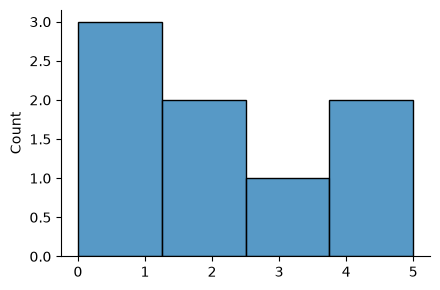

In [63]:
sns.displot(x=a, kind="hist", height=3, aspect=1.5)
plt.show()

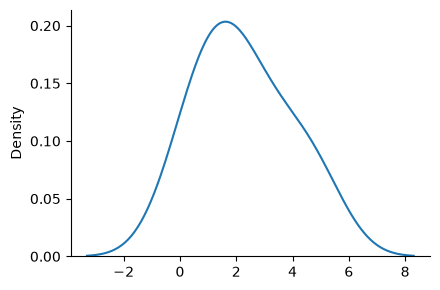

In [64]:
sns.displot(x=a, kind="kde", height=3, aspect=1.5)
plt.show()

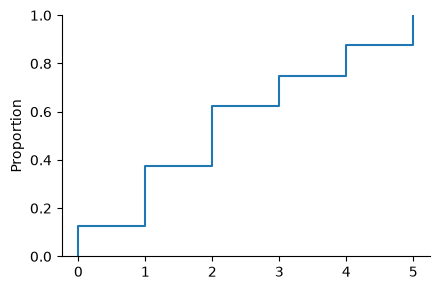

In [65]:
sns.displot(x=a, kind="ecdf", height=3, aspect=1.5)
plt.show()

**怎么读**：
- 直方图告诉你“每个区间有多少个样本”；
- KDE 是直方图的平滑版，曲线下方面积为 1，可能延伸到数据范围之外；
- ECDF 在某个 x 处的高度 = 样本中 ≤ x 的比例，最后一定到 1。

## 18. 常见统计分布

| 分布 | 类型 | 关键参数 | 典型用途 |
|---|---|---|---|
| 正态 Normal | 连续 | `loc` 均值，`scale` 标准差 | 身高、测量误差 |
| 二项 Binomial | 离散 | `n` 试验次数，`p` 成功概率 | 抛硬币正面次数 |
| 泊松 Poisson | 离散 | `lam` 单位时间发生次数 | 每小时到达的顾客数 |
| 指数 Exponential | 连续 | `scale = 1 / rate` | 两次事件之间的等待时间 |
| 逻辑 Logistic | 连续 | `loc` 位置，`scale` 尺度 | 逻辑回归、神经网络 |
| 均匀 Uniform | 连续 | `low`，`high` | 每个值等可能 |
| 多项 Multinomial | 离散 | `n`，`pvals` | 掷骰子各面的次数 |

> 下面每个例子都用 `rng = np.random.default_rng(42)` 重新开始，保证单元格单独重跑也能复现。

### 18.1 加权随机：`choice` 的 `p`

`p` 给出每个候选值的概率，长度要和候选值一样，并且总和为 1。

In [66]:
rng = np.random.default_rng(42)

x = rng.choice([3, 5, 7, 9], p=[0.1, 0.3, 0.5, 0.1], size=(3, 4))
print(x)

[[7 7 7 7]
 [3 9 7 7]
 [5 7 5 9]]


In [67]:
# 用大样本验证频率确实接近设定的概率
samples = rng.choice([3, 5, 7, 9], p=[0.1, 0.3, 0.5, 0.1], size=10000)
values, counts = np.unique(samples, return_counts=True)
for v, c in zip(values, counts):
    print(f"value {v}: {c / len(samples):.3f}")

value 3: 0.098
value 5: 0.305
value 7: 0.498
value 9: 0.098


### 18.2 正态分布 Normal

`loc` 是均值（默认 0），`scale` 是标准差（默认 1），`size` 是输出形状。

In [68]:
rng = np.random.default_rng(42)

x = rng.normal(loc=1, scale=2, size=(2, 3))
print(x)

[[ 1.60943416 -1.07996821  2.50090239]
 [ 2.88112943 -2.90207038 -1.60435901]]


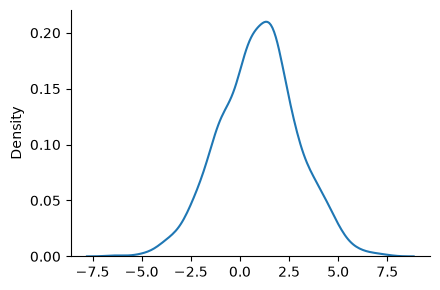

In [69]:
samples = rng.normal(loc=1, scale=2, size=1000)
sns.displot(x=samples, kind="kde", height=3, aspect=1.5)
plt.show()

正态分布约 68% 的数据落在 `loc ± scale`，约 95% 落在 `loc ± 2*scale`，约 99.7% 落在 `loc ± 3*scale`。

### 18.3 二项分布 Binomial

做 `n` 次独立试验，每次成功概率为 `p`，结果是**成功次数**（0 到 n 的整数）。

In [70]:
rng = np.random.default_rng(42)

x = rng.binomial(n=10, p=0.5, size=10)
print(x)

[6 5 7 6 3 8 6 6 3 5]


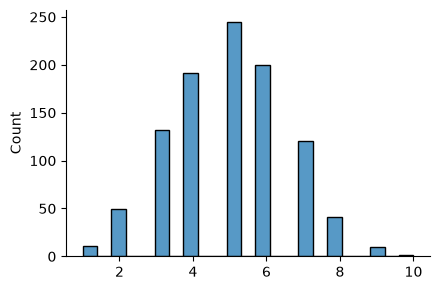

In [71]:
sns.displot(x=rng.binomial(n=10, p=0.5, size=1000),
            height=3, aspect=1.5)
plt.show()

二项分布的均值是 `n*p`，方差是 `n*p*(1-p)`。`n=1` 时就是伯努利分布（抛一次硬币）。

### 18.4 泊松分布 Poisson

描述**固定时间/空间内事件发生次数**，`lam` 是平均发生率。均值 = 方差 = `lam`。

In [72]:
rng = np.random.default_rng(42)

x = rng.poisson(lam=2, size=10)
print(x)

[4 3 3 2 1 5 2 0 1 3]


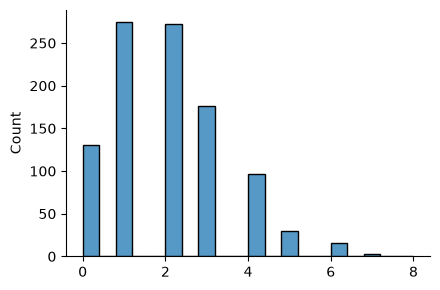

In [73]:
sns.displot(x=rng.poisson(lam=2, size=1000),
            height=3, aspect=1.5)
plt.show()

### 18.5 指数分布 Exponential

描述**两次事件之间的等待时间**，是泊松过程的“时间间隔”版本。`scale` 是平均等待时间，等于 `1 / rate`。

In [74]:
rng = np.random.default_rng(42)

x = rng.exponential(scale=2, size=(2, 3))
print(x)

[[4.80841721 4.67237931 4.769522  ]
 [0.55958858 0.1728748  2.90532103]]


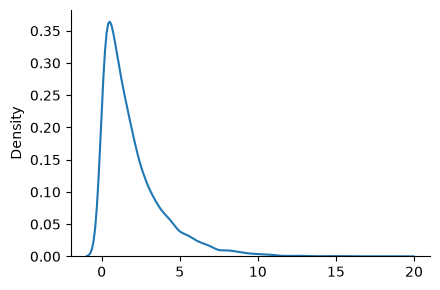

In [75]:
samples = rng.exponential(scale=2, size=10000)
sns.displot(x=samples, kind="kde", height=3, aspect=1.5)
plt.show()

> **联系**：如果事件按泊松过程发生（平均每个区间 `lam` 次），那么相邻事件的时间间隔服从 `scale = 1/lam` 的指数分布。

### 18.6 逻辑分布 Logistic

形状像正态分布，但**尾部更重**；它的累积分布函数是 logistic 函数，因此出现在逻辑回归和神经网络里。`loc` 是中心位置，`scale` 控制平坦程度。

In [76]:
rng = np.random.default_rng(42)

x = rng.logistic(loc=1, scale=2, size=(2, 3))
print(x)

[[ 3.46157126  0.50856981  4.60738654]
 [ 2.66959168 -3.52732771  8.37881783]]


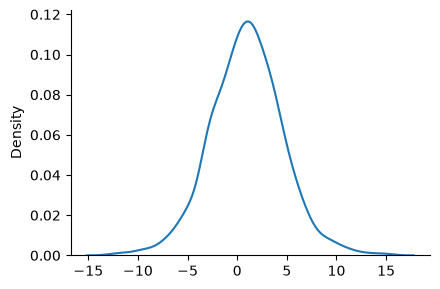

In [77]:
samples = rng.logistic(loc=1, scale=2, size=1000)
sns.displot(x=samples, kind="kde", height=3, aspect=1.5)
plt.show()

### 18.7 均匀分布 Uniform

`low` 到 `high` 之间每个值等可能，默认是 `[0, 1)`。

In [78]:
rng = np.random.default_rng(42)

x = rng.uniform(low=2, high=5, size=10)
print(x)

[4.32186815 3.31663532 4.57579376 4.09210409 2.28253204 4.92686705
 4.28341911 4.35819292 2.3843409  3.35115781]


连续均匀分布取到**某个具体值**的概率是 0；我们通常说“落在某个区间内的概率与区间长度成正比”。

### 18.8 多项分布 Multinomial

二项分布只有“成功/失败”两种结果；多项分布有 k 种结果，返回**每种结果出现的次数**。

- `n`：实验次数；
- `pvals`：每个类别的概率，长度 k，总和为 1；
- 输出形状：`(size, k)`，每一行加起来等于 `n`。

In [79]:
rng = np.random.default_rng(42)

# 掷 6 次骰子，记录每个点数出现的次数；做 3 组实验
x = rng.multinomial(n=6, pvals=[1/6] * 6, size=3)
print(x)
print("每行总和:", x.sum(axis=1))

[[2 1 2 1 0 0]
 [0 3 1 1 0 1]
 [1 1 2 1 1 0]]
每行总和: [6 6 6]


**注意**：`multinomial` 返回的是**每个类别的计数**，不是每次实验的结果序列。如果要模拟“掷 6 次骰子每次的点数”，应该用 `rng.integers(1, 7, size=6)`。

## 19. ufunc：向量化函数

ufunc（Universal Function）是 NumPy 中**逐元素**作用于 ndarray 的函数，底层用 C 实现，比 Python 循环快得多，并且自动支持广播和类型转换。

In [80]:
x = [1, 2, 3, 4]
y = [4, 5, 6, 7]

# 纯 Python：显式循环
z = []
for i, j in zip(x, y):
    z.append(i + j)
print("loop   :", z)

# NumPy ufunc：一行完成
print("np.add :", np.add(x, y))

loop   : [5, 7, 9, 11]
np.add : [ 5  7  9 11]


In [81]:
a = np.array([1, 4, 9])

print("np.sqrt(a)     :", np.sqrt(a))
print("np.add(a, 1)   :", np.add(a, 1))
print("np.maximum(a, 5):", np.maximum(a, 5))
print("np.exp(a)      :", np.exp(a))

np.sqrt(a)     : [1. 2. 3.]
np.add(a, 1)   : [ 2  5 10]
np.maximum(a, 5): [5 5 9]
np.exp(a)      : [2.71828183e+00 5.45981500e+01 8.10308393e+03]


### 自定义 ufunc：`np.frompyfunc`

先写普通 Python 函数，再用 `frompyfunc` 注册成 ufunc。参数依次是：函数、输入数组个数、输出数组个数。

In [82]:
def myAdd(x, y, z):
    return x + y + z

triAdd = np.frompyfunc(myAdd, 3, 1)

res = triAdd([1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12])
print(res)
print("dtype:", res.dtype)
print("转成 int:", res.astype(int))

[15 18 21 24]
dtype: object
转成 int: [15 18 21 24]


`frompyfunc` 的结果 dtype 是 `object`，做数值计算前通常要 `astype` 一下。

### ufunc 的常用方法

| 方法 | 作用 |
|---|---|
| `np.add.reduce(a)` | 沿数组累加，等价于 `a.sum()` |
| `np.add.accumulate(a)` | 累积和，返回和原数组等长的数组 |
| `np.multiply.outer(a, b)` | 外积，结果形状 `(len(a), len(b))` |

In [83]:
a = np.arange(1, 6)
print("a:", a)
print("reduce     :", np.add.reduce(a))
print("accumulate :", np.add.accumulate(a))
print("outer:\n", np.multiply.outer(a, a))

a: [1 2 3 4 5]
reduce     : 15
accumulate : [ 1  3  6 10 15]
outer:
 [[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]
 [ 4  8 12 16 20]
 [ 5 10 15 20 25]]


## 20. 速查表与常见坑

### 20.1 数组速查

| 想要 | 写法 |
|---|---|
| 从 list 创建 | `np.array([1, 2, 3])` |
| 全 0 / 全 1 | `np.zeros(shape)` / `np.ones(shape)` |
| 填充固定值 | `np.full(shape, value)` |
| 等差数列（不含尾） | `np.arange(start, stop, step)` |
| 等距点（含两端） | `np.linspace(start, stop, n)` |
| 查看形状 / 类型 | `x.shape` / `x.dtype` |
| 改变形状（常为视图） | `x.reshape(2, 3)` |
| 就地改大小 | `x.resize((2, 3), refcheck=False)` |
| 增加一个维度 | `x[None, :]` / `x[:, None]` |
| 转置 | `x.T` / `np.transpose(x)` |
| 拼接 | `np.concatenate` / `np.vstack` / `np.hstack` |
| 拆分 | `np.split` / `np.vsplit` / `np.hsplit` |
| 排序（返回副本） | `np.sort(x)` |
| 排序（就地） | `x.sort()` |
| 排序下标 | `np.argsort(x)` |

### 20.2 随机 API 速查

| 想要 | 写法 |
|---|---|
| 创建可复现生成器 | `rng = np.random.default_rng(seed)` |
| [0,1) 浮点 | `rng.random(shape)` |
| 整数 [low, high) | `rng.integers(low, high, size=shape)` |
| 正态 | `rng.normal(loc, scale, size=shape)` |
| 二项 | `rng.binomial(n, p, size=shape)` |
| 泊松 | `rng.poisson(lam, size=shape)` |
| 指数 | `rng.exponential(scale, size=shape)` |
| 逻辑 | `rng.logistic(loc, scale, size=shape)` |
| 均匀 | `rng.uniform(low, high, size=shape)` |
| 多项 | `rng.multinomial(n, pvals, size=shape)` |
| 从数组抽样 | `rng.choice(x, size=..., replace=..., p=...)` |
| 打乱副本 / 原地打乱 | `rng.permutation(x)` / `rng.shuffle(x)` |

### 20.3 常见坑

1. **切片是视图**：改切片会改原数组；要独立就 `.copy()`。
2. **花式索引是副本**：`x[[1, 3, 5]]` 不与原数组共享内存。
3. **`*` 是逐元素**：矩阵乘法用 `@` 或 `np.dot`。
4. **多条件要用 `&` / `|` / `~`**，并且每个条件加括号。
5. **切片 `stop` 不包含**：`x[:5]` 是下标 0 到 4。
6. **整数数组不能存小数**：赋值会被截断，先 `astype(float)`。
7. **`x.sort()` 就地改，`np.sort(x)` 返回副本**。
8. **`axis=0` 压行（按列出结果），`axis=1` 压列（按行出结果）**。
9. **`reshape` 元素总数必须不变**，否则 `ValueError`；`resize` 可以改变元素总数。
10. **`rng.random((3, 4))` 要传 tuple**，不是 `rng.random(3, 4)`。
11. **`randint` / `integers` 的上界不包含**：`integers(0, 10)` 只到 9。
12. **`shuffle` 原地改，`permutation` 返回副本**。
13. **`choice` 默认有放回**，要无放回写 `replace=False`。
14. **`multinomial` 返回每类计数**，每行总和为 `n`。
15. **随机种子只对同一套 API 保证复现**：legacy 和 Generator 的序列不同。

---

**Done.** 建议现在执行 `Kernel → Restart & Run All`，从头跑一遍，再遮住答案完成四个 Exercise。

遇到结果和预期不一致时，先检查两件事：**`shape`** 和 **`dtype`**。NumPy 里绝大多数“为什么报错 / 为什么结果不对”，都能从这两个属性找到线索。